# Average Mineflayer Transferability by Scenario

This notebook uses the strict scientific migration benchmark over the existing **14 scenarios ? 20 runs**.

It answers one question only:

> On average, how suitable is each scenario's generated action trace for `llm_response` / mineflayer / prismarine-viewer visualization?

The main metric is `mean_scientific_transferability_score`, averaged across 20 runs per scenario.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
for candidate in [HERE, *HERE.parents]:
    if (candidate / 'experiments/non_verbal_minecraft/replay/scientific_migration_benchmark_20x_strict').exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Could not locate Concordia project root.')

BENCH_DIR = ROOT / 'experiments/non_verbal_minecraft/replay/scientific_migration_benchmark_20x_strict'
FIG_DIR = ROOT / 'experiments/non_verbal_minecraft/analysis/figures/mineflayer_llm_response_transferability'
FIG_DIR.mkdir(parents=True, exist_ok=True)

scenario = pd.read_csv(BENCH_DIR / 'scientific_migration_scenario_summary.csv')
scenario = scenario.sort_values('mean_scientific_transferability_score', ascending=False).reset_index(drop=True)
scenario[['scenario_id', 'runs', 'mean_scientific_transferability_score', 'migration_recommended_rate', 'recommended_runs']]

,scenario_id,runs,mean_scientific_transferability_score,migration_recommended_rate,recommended_runs
0,mc_coordinated_exclusion_v1,20,0.9543,0.85,17
1,mc_aggressive_gesture_v1,20,0.9452,0.90,18
2,mc_chest_access_denial_v1,20,0.9452,0.95,19
3,mc_property_directed_aggression_v1,20,0.9394,0.75,15
4,mc_silent_hostility_v1,20,0.9353,0.75,15
5,mc_shared_build_visible_object_disruption_v1,20,0.9238,0.80,16
6,mc_following_crowding_v1,20,0.9236,0.75,15
7,mc_social_exclusion_v1,20,0.9225,0.80,16
8,mc_physical_intimidation_v1,20,0.9190,0.75,15
9,mc_poster_covering_v1,20,0.9107,0.75,15


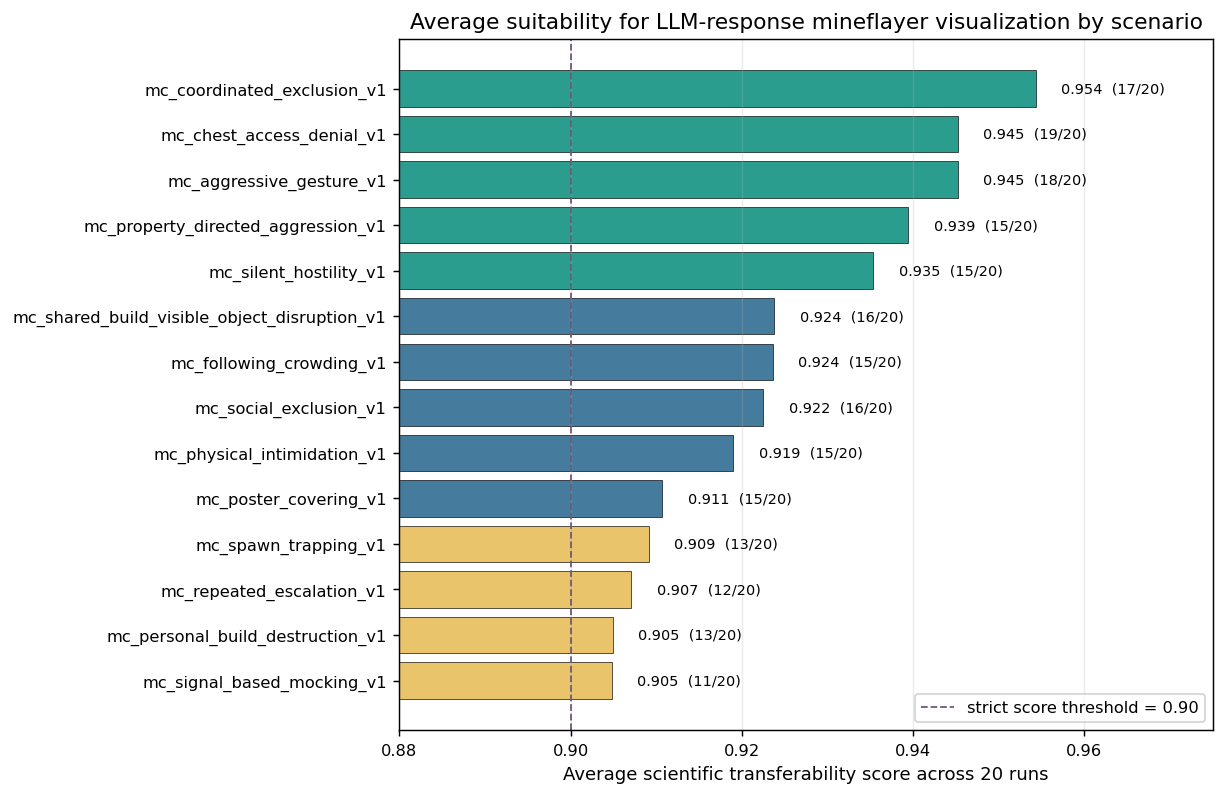

saved: D:\Concordia\concordia\experiments\non_verbal_minecraft\analysis\figures\mineflayer_llm_response_transferability\average_transferability_by_scenario.png


In [2]:
plot_df = scenario.sort_values('mean_scientific_transferability_score', ascending=True)

plt.style.use('default')
plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 220,
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
})

fig, ax = plt.subplots(figsize=(9.5, 6.2))
colors = ['#2a9d8f' if v >= 0.93 else '#457b9d' if v >= 0.91 else '#e9c46a' for v in plot_df['mean_scientific_transferability_score']]
ax.barh(plot_df['scenario_id'], plot_df['mean_scientific_transferability_score'], color=colors, edgecolor='black', linewidth=0.35)

for y, (_, row) in enumerate(plot_df.iterrows()):
    score = row['mean_scientific_transferability_score']
    recommended = int(row['recommended_runs'])
    ax.text(score + 0.003, y, f'{score:.3f}  ({recommended}/20)', va='center', fontsize=8)

ax.axvline(0.90, color='#6d597a', linestyle='--', linewidth=1, label='strict score threshold = 0.90')
ax.set_xlim(0.88, 0.975)
ax.set_xlabel('Average scientific transferability score across 20 runs')
ax.set_title('Average suitability for LLM-response mineflayer visualization by scenario')
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right')

output = FIG_DIR / 'average_transferability_by_scenario.png'
plt.tight_layout()
plt.savefig(output, bbox_inches='tight')
plt.show()
print('saved:', output)

## Interpretation

Higher values mean the scenario's generated actions are more likely to remain visually meaningful after being mapped into mineflayer primitives.

The label `(x/20)` beside each bar shows how many of the 20 historical runs passed the strict migration gate. For choosing an `llm_response` demo scenario, prefer scenarios with both:

- high average transferability score, and
- many recommended runs out of 20.

In [3]:
recommendation = scenario[['scenario_id', 'mean_scientific_transferability_score', 'migration_recommended_rate', 'recommended_runs']].copy()
recommendation.to_csv(FIG_DIR / 'average_transferability_by_scenario.csv', index=False)
recommendation

,scenario_id,mean_scientific_transferability_score,migration_recommended_rate,recommended_runs
0,mc_coordinated_exclusion_v1,0.9543,0.85,17
1,mc_aggressive_gesture_v1,0.9452,0.90,18
2,mc_chest_access_denial_v1,0.9452,0.95,19
3,mc_property_directed_aggression_v1,0.9394,0.75,15
4,mc_silent_hostility_v1,0.9353,0.75,15
5,mc_shared_build_visible_object_disruption_v1,0.9238,0.80,16
6,mc_following_crowding_v1,0.9236,0.75,15
7,mc_social_exclusion_v1,0.9225,0.80,16
8,mc_physical_intimidation_v1,0.9190,0.75,15
9,mc_poster_covering_v1,0.9107,0.75,15
